In [49]:
from pythonjsonlogger import exception
from scipy import stats
import pynbody
import warnings
import traceback
import logging

import matplotlib


import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from matplotlib.cm import ScalarMappable

from scipy.optimize import curve_fit
from scipy.interpolate import Rbf, LinearNDInterpolator, NearestNDInterpolator
import pynbody
import pymp
import pynbody
import pymp
import re
import os
import sys
import gc
import pickle
import traceback
import numpy as np
from config import (db_connection, sys_path, pickle_file, ba_s_key, ca_s_key,
                    results_output_directory)

os.environ['TANGOS_DB_CONNECTION'] =db_connection
os.environ['TANGOS_PROPERTY_MODULES'] = 'mytangosproperty'
sys.path.append(sys_path)
import tangos

In [6]:

file = 'ellipse_data_n_100.pickle'
with open(file,'rb') as f:
    ellipse_dict = pickle.load(f)

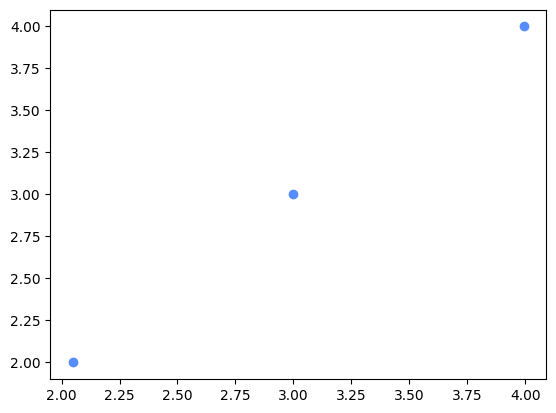

In [13]:
r = []
for sim in ellipse_dict:
    for halo in ellipse_dict[sim]:

        for orientation in ellipse_dict[sim][halo]:
            #print(orientation)
            #print(ellipse_dict[sim][halo][orientation])
            dict = ellipse_dict[sim][halo][orientation]
            plt.scatter(dict['r_over_reff'],dict['target_ratios'])
            r.append(dict['r_over_reff'][2])
            break
        break
    break

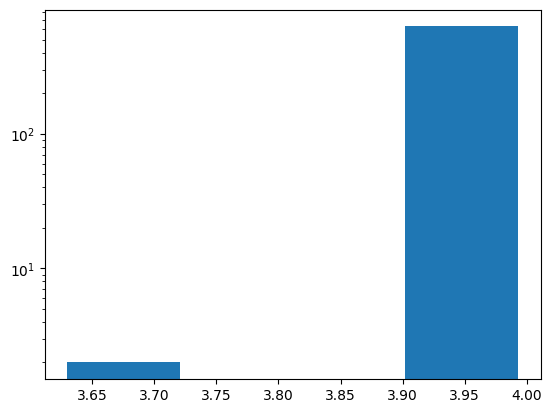

In [101]:

plt.hist(r,bins = 4)
plt.yscale('log')

In [89]:
np.nanmean(r),np.nanstd(r)

(np.float64(2.048745157859209), np.float64(0.0074096679170146265))

In [93]:
np.nanmin(r)

np.float64(1.8627639691774647)

In [75]:
print(orientation)

0099_t+0.000000_p+0.000000


In [16]:
assert np.isfinite(ellipse_dict[sim][halo]['0099_t+0.000000_p+0.000000']['r_kpc'][0])

In [19]:
assert np.isfinite(ellipse_dict['cptmarvel.cosmo25cmb.4096g5HbwK1BH']['cptmarvel.cosmo25cmb.4096g5HbwK1BH/%/halo_8']['0099_t+0.000000_p+0.000000']['r_kpc'][0])

AssertionError: 

In [22]:
ellipse_dict['cptmarvel.cosmo25cmb.4096g5HbwK1BH']['cptmarvel.cosmo25cmb.4096g5HbwK1BH/%/halo_8']['0099_t+0.000000_p+0.000000']

{'eps': array([nan, nan, nan]),
 'r_kpc': array([nan, nan, nan]),
 'r_over_reff': array([nan, nan, nan]),
 'target_ratios': [2, 3, 4]}

In [4]:
file = '/home/bk639/MCMC-deprojection/caches/i.isophote_cache_cptmarvel.cosmo25cmb.4096g5HbwK1BH_n100/iBandIsophoteAnalysis_halo8.pkl'
with open(file,'rb') as f:
    isophote_params = pickle.load(f)

In [5]:
isophote_params

{'0011_t+0.523599_p+5.585054': [],
 '0025_t+1.221730_p+0.000000': [],
 '0030_t+1.221730_p+1.963495': [],
 '0024_t+0.872665_p+5.799863': [],
 '0006_t+0.523599_p+2.094395': [],
 '0007_t+0.523599_p+2.792527': [],
 '0017_t+0.872665_p+2.416610': [],
 '0018_t+0.872665_p+2.899932': [],
 '0020_t+0.872665_p+3.866576': [],
 '0035_t+1.221730_p+3.926991': [],
 '0012_t+0.872665_p+0.000000': [],
 '0026_t+1.221730_p+0.392699': [],
 '0016_t+0.872665_p+1.933288': [],
 '0002_t+0.174533_p+4.188790': [],
 '0003_t+0.523599_p+0.000000': [],
 '0001_t+0.174533_p+2.094395': [],
 '0032_t+1.221730_p+2.748894': [],
 '0027_t+1.221730_p+0.785398': [],
 '0005_t+0.523599_p+1.396263': [],
 '0014_t+0.872665_p+0.966644': [],
 '0031_t+1.221730_p+2.356194': [],
 '0015_t+0.872665_p+1.449966': [],
 '0034_t+1.221730_p+3.534292': [],
 '0028_t+1.221730_p+1.178097': [],
 '0013_t+0.872665_p+0.483322': [],
 '0023_t+0.872665_p+5.316541': [],
 '0000_t+0.174533_p+0.000000': [],
 '0004_t+0.523599_p+0.698132': [],
 '0029_t+1.221730_p+

In [50]:
sims = tangos.all_simulations()

In [96]:
path = sims[3].timesteps[0].path
base = '/home/bk639/data/CDM_z0/'
fullpath = os.path.join(base,path)
print(fullpath)



/home/bk639/data/CDM_z0/h229.cosmo50PLK.3072gst5HbwK1BH/h229.cosmo50PLK.3072gst5HbwK1BH.004096/h229.cosmo50PLK.3072gst5HbwK1BH.004096


AttributeError: 'Simulation' object has no attribute 'handler'

In [95]:
pynbody.load(fullpath)

OSError: File PosixPath('/home/bk639/data/CDM_z0/h229.cosmo50PLK.3072gst5HbwK1BH/h229.cosmo50PLK.3072gst5HbwK1BH.004096/h229.cosmo50PLK.3072gst5HbwK1BH.004096/halo_1'): format not understood or does not exist

In [47]:
Mhalo = []
Mstar = []
for sim in sims:
    name = sim.basename
    if name.startswith('r'):
        if name.startswith == 'rouge':
            continue
        print(sim)
        halo = sim.timesteps[0].halos[0]
        print(halo.keys())
        Mhalo.append(halo['Mhalo'])
        Mstar.append(halo['M_star'])

<Simulation("r1000.romulus25.3072g1HsbBH")>
['#ID', 'numSubStruct', 'Mhalo', 'npart', 'Xc', 'Yc', 'Zc', 'VXc', 'VYc', 'VZc', 'Rhalo', 'Rmax', 'r2', 'mbp_offset', 'com_offset', 'Vmax', 'v_esc', 'sigV', 'lambda', 'lambdaE', 'Lx', 'Ly', 'Lz', 'b', 'c', 'Eax', 'Eay', 'Eaz', 'Ebx', 'Eby', 'Ebz', 'Ecx', 'Ecy', 'Ecz', 'ovdens', 'nbins', 'fMhires', 'Ekin', 'Epot', 'SurfP', 'Phi0', 'cNFW', 'n_gas', 'M_gas', 'lambda_gas', 'lambdaE_gas', 'Lx_gas', 'Ly_gas', 'Lz_gas', 'b_gas', 'c_gas', 'Eax_gas', 'Eay_gas', 'Eaz_gas', 'Ebx_gas', 'Eby_gas', 'Ebz_gas', 'Ecx_gas', 'Ecy_gas', 'Ecz_gas', 'Ekin_gas', 'Epot_gas', 'n_star', 'M_star', 'lambda_star', 'lambdaE_star', 'Lx_star', 'Ly_star', 'Lz_star', 'b_star', 'c_star', 'Eax_star', 'Eay_star', 'Eaz_star', 'Ebx_star', 'Eby_star', 'Ebz_star', 'Ecx_star', 'Ecy_star', 'Ecz_star', 'Ekin_star', 'Epot_star', 'n_gas', 'n_star', 'n_dm', 'a_s', 'b_s', 'c_s', 'rbins_s', 'Mdyn', 'a_s_i', 'b_s_i', 'c_s_i', 'rbins_s_i', 'childHalo', 'childHalo', 'childHalo', 'childHalo', '

KeyError: "No such property 'Mhalo'"

/tmp/ipykernel_3533172/1537238904.py:1: RuntimeWarning: divide by zero encountered in log10
  plt.scatter(np.log10(Mhalo),np.log10(Mstar),c='k')


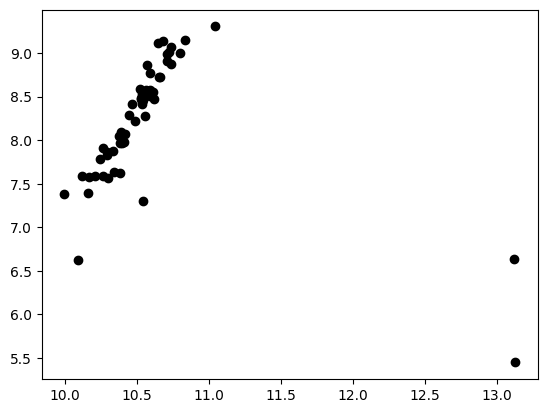

In [48]:
plt.scatter(np.log10(Mhalo),np.log10(Mstar),c='k')

In [39]:
Mhalo

[]